# 01 · Fundamentos C++ aplicados al monitor

[Índice](00_indice_y_recorrido.ipynb) · [Siguiente](02_librerias_constantes_y_estado.ipynb)

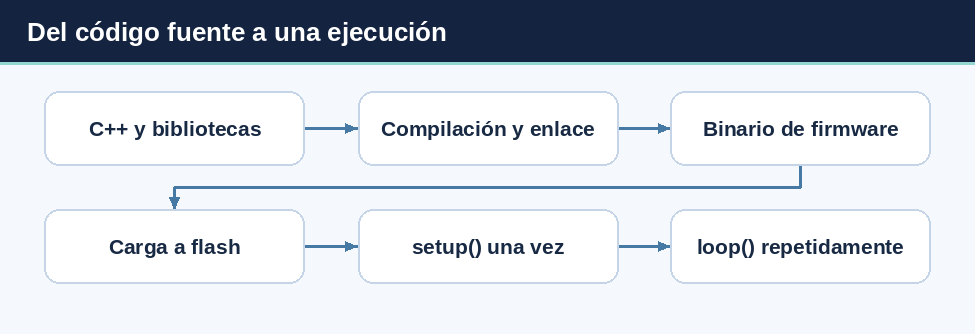

## Declaración, definición, llamada, parámetro y argumento

Una declaración anuncia una función: `float readGasPpm(float temperature, float humidity);`.
La definición contiene su cuerpo entre `{}`. La llamada `readGasPpm(25.0f, 67.5f)` la ejecuta.
`temperature` y `humidity` son **parámetros**: nombres que reciben datos. `25.0f` y `67.5f`
son **argumentos**: valores concretos de una llamada. En el proyecto se pasan variables como
argumentos, no solo literales.

`void` significa que la función no devuelve un valor. `return;` termina una función `void`;
`return NAN;` termina una función numérica con un valor especial. Los prototipos están antes
de `setup()`; las definiciones propias están debajo de `loop()`. Esto permite llamar funciones
que todavía no aparecieron definidas en el archivo.

## `constexpr`, `const` y `#define`

| Construcción | Qué expresa | Ejemplo del proyecto |
|---|---|---|
| `constexpr` | Variable constante cuya inicialización debe ser una expresión constante. | `constexpr uint8_t PIN_DHT = 4;` |
| `const` | No permite modificar el objeto mediante ese nombre después de inicializarlo; el valor puede obtenerse al ejecutar. | `const float temperature = dhtSensor.readTemperature();` |
| `#define` | Sustitución del preprocesador, antes de compilar; por sí misma no es una variable tipada. | `#define TFT_MOSI 11` |

`constexpr` en estas variables implica `const`, pero `const` no siempre implica una expresión
constante. Un `const int` inicializado con un literal puede servir como constante de compilación;
no es correcto decir que todos los `const` se calculan en ejecución. En cambio, una lectura del
sensor no puede obtenerse al compilar. El tipo Arduino `String` usado aquí construye los topics
al ejecutar la inicialización; por eso se emplea `const String` y no `constexpr String`.

Elegir `constexpr` no garantiza por sí solo que un objeto no ocupe RAM. La ubicación y eliminación
de objetos dependen del compilador, del tipo y de cómo se utilizan.

```cpp
constexpr unsigned long SAMPLE_INTERVAL_MS = 2000;
const float temperature = dhtSensor.readTemperature();
// temperature = 30.0f;  // Error: se intenta modificar una constante.
// constexpr float invalid = dhtSensor.readTemperature(); // No es expresión constante.
```

## Tipos, literales y memoria

- `uint8_t`: entero sin signo de 8 bits; suficiente para estos GPIO.
- `unsigned long`: entero sin signo usado con `millis()`; en esta plataforma es de 32 bits.
- `size_t`: entero sin signo para tamaños y posiciones en memoria/archivos.
- `unsigned` abrevia `unsigned int`; se usa para contar muestras.
- `float`: número de punto flotante; `5.0f` especifica un literal `float`.
- `bool`: `true` o `false`; no son las cadenas `"true"` y `"false"`.
- `char DEVICE_ID[]`: arreglo de caracteres terminado en `\0`; el tamaño se deduce del literal.
- `String`: clase de Arduino para texto de longitud variable; no es un `char[]`.
- `byte`: tipo de byte usado por Arduino en el callback MQTT.
- `time_t`: representación de tiempo de la biblioteca C; `struct tm` separa año, mes, hora, etc.
- `NAN`: valor numérico inválido; no es cero y no debe compararse usando `== NAN`.
  `isfinite(value)` descarta NaN e infinitos.

El sufijo de `float` cambia el tipo del literal, no sus unidades físicas. En el código las unidades
se establecen por el cálculo y por nombres como `SAMPLE_INTERVAL_MS`.

## Punteros y referencias

`const char *text` apunta a caracteres que no deben modificarse mediante ese puntero.
No significa que el puntero no pueda apuntar después a otro lugar. `const char *const` agregaría
esa segunda restricción. `char *topic` y `byte *payload` reciben direcciones de buffers de MQTT.
El payload tiene una longitud explícita: no hay que suponer que termina en `\0`.

`JsonDocument &document` recibe una referencia mutable: la función llena el documento original.
`const String &timestamp` recibe una referencia de solo lectura y evita copiar la cadena.
`wifiClient` se pasa al constructor de `PubSubClient` para que este use ese transporte TCP.
`String.c_str()` ofrece un puntero al contenido de la cadena; no se debe conservar después de
que la cadena se destruya o cambie de forma que invalide su almacenamiento.

## Operadores y flujo de control

`!` niega una condición. `&&` y `||` cortocircuitan: el segundo operando se evalúa solo si hace
falta. Así, `!file || deserializeJson(...)` no intenta deserializar un archivo que no abrió.
`==` compara; `=` asigna. `+=` acumula. `++referenceCount` incrementa. `condition ? a : b`
es el operador ternario. `+` concatena cuando interviene `String`; entre números suma.

En `configuration["MQTT_PORT"] | 1883`, ArduinoJson **sobrecarga** `|` para expresar un valor
predeterminado; aquí no se está realizando un OR de bits entre el puerto y 1883.
`as<const char *>()`, `is<const char *>()` y `to<JsonObject>()` son llamadas con parámetros de
plantilla: convierten/consultan tipos y crean objetos JSON, respectivamente.

`sizeof(uint32_t)` mide bytes del tipo; `strlen(CSV_HEADER)` cuenta caracteres hasta `\0`
y no incluye ese terminador. `sizeof(buffer)` conoce la capacidad completa de un arreglo local.
Los casts `(unsigned long)` adaptan los resultados aleatorios a `%lx` de `snprintf`.

Las salidas tempranas reducen anidación: se rechazan primero estados que impiden continuar.
Las llaves y la indentación de cuatro espacios hacen explícitos los bloques.

```cpp
if (!mqttClient.connected() ||
    !mqttClient.publish(processedTopic.c_str(), json.c_str())) {
    saveMeasurementCsv(timestamp, temperature, humidity, gasPpm);
}
// Si no hay conexión, publish no se evalúa y se guarda directamente.
```

## Clase, objeto, instancia y método

Una clase define un tipo con datos y operaciones. `DHT` es una clase; `dhtSensor` es una instancia.
El constructor `DHT(PIN_DHT, DHT11)` recibe los argumentos GPIO4 y tipo de sensor. El método
`dhtSensor.readHumidity()` trabaja sobre esa instancia. Una función libre como `readGasPpm()`
no pertenece a una clase propia del proyecto. `display.init()` no es lo mismo que construir
`display`: la inicialización del hardware ocurre después, en `setup()`.

Los objetos globales viven durante toda la ejecución. Las variables locales viven dentro de su
ámbito. `const` limita modificaciones, pero no sustituye el diseño del ciclo de vida de un objeto.

[Índice](00_indice_y_recorrido.ipynb) · [Siguiente](02_librerias_constantes_y_estado.ipynb)